In [1]:
import sys
from pathlib import Path

root = Path(r"C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster")
sys.path.insert(0, str(root))

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config

images = root / "images"
images.mkdir(exist_ok=True)

conn = sqlite3.connect(config.DB_PATH)
fc = pd.read_sql("select * from forecast_peak_2025", conn, parse_dates=["date"]).set_index("date")

ops = pd.read_sql("select uph from ops_synthetic", conn)
target_uph = round(ops["uph"].median(), 1)
print("Target units per hour:", target_uph)
fc.head()

Target units per hour: 93.9


,actual_parcels,forecast_parcels
date,,
2025-11-01,20855,20412.472342
2025-11-02,14281,13600.472319
2025-11-03,27898,28452.397980
2025-11-04,28795,26265.773224
2025-11-05,26232,23992.295496


In [2]:
HOURS_PER_ASSOCIATE = 8     # productive hours each person works per day
ABSENCE_RATE = 0.10         # share of booked staff who don't show up
FORECAST_BUFFER = 0.15    # extra volume planned for, to cover forecast error

def headcount_needed(parcels):
    labour_hours = parcels / target_uph
    people = labour_hours / HOURS_PER_ASSOCIATE / (1 - ABSENCE_RATE)
    return np.ceil(people)

# Plan from the FORECAST (with a safety buffer)
fc["planned_headcount"] = headcount_needed(fc["forecast_parcels"] * (1 + FORECAST_BUFFER))

# What was REALLY needed, using the actual volume
fc["needed_headcount"] = headcount_needed(fc["actual_parcels"])

fc["gap"] = fc["planned_headcount"] - fc["needed_headcount"]
fc[["forecast_parcels", "actual_parcels", "planned_headcount", "needed_headcount", "gap"]].head

<bound method NDFrame.head of             forecast_parcels  actual_parcels  planned_headcount  \
date                                                              
2025-11-01      20412.472342           20855               35.0   
2025-11-02      13600.472319           14281               24.0   
2025-11-03      28452.397980           27898               49.0   
2025-11-04      26265.773224           28795               45.0   
2025-11-05      23992.295496           26232               41.0   
...                      ...             ...                ...   
2025-12-27      29434.637949           30909               51.0   
2025-12-28      19023.554762           20908               33.0   
2025-12-29      36410.096584           42671               62.0   
2025-12-30      35263.724138           39351               60.0   
2025-12-31      33337.756255           39481               57.0   

            needed_headcount  gap  
date                               
2025-11-01              31

In [3]:
short_days = (fc["gap"] < 0).sum()
print(f"Days short-staffed: {short_days} of {len(fc)}")
print("Worst shortfall:", int(fc["gap"].min()), "associates")
print("Average over-plan on other days:", round(fc.loc[fc["gap"] >= 0, "gap"].mean(), 1), "associates")
print("Peak planned headcount:", int(fc["planned_headcount"].max()),
      "on", fc["planned_headcount"].idxmax().date())

Days short-staffed: 5 of 61
Worst shortfall: -4 associates
Average over-plan on other days: 3.8 associates
Peak planned headcount: 89 on 2025-12-01


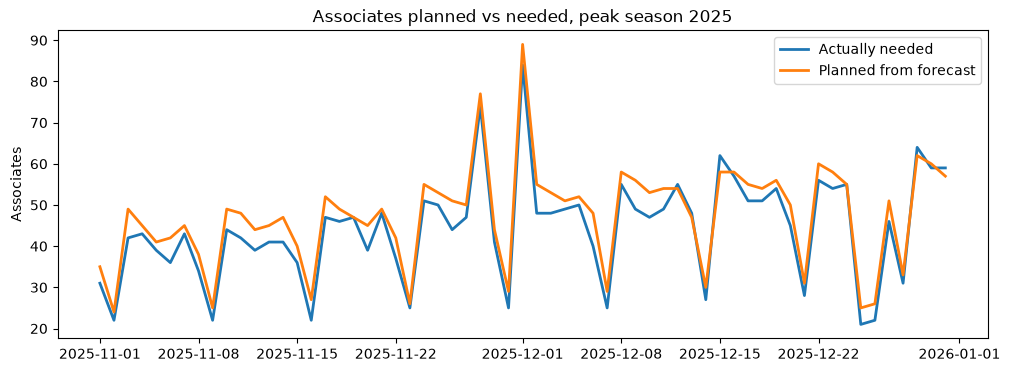

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(fc.index, fc["needed_headcount"], label="Actually needed", linewidth=2)
ax.plot(fc.index, fc["planned_headcount"], label="Planned from forecast", linewidth=2)
ax.set_title("Associates planned vs needed, peak season 2025")
ax.set_ylabel("Associates")
ax.legend()

In [5]:
root = Path.cwd()
while not (root / "run_ingestion.py").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the project's notebooks folder.")
    root = root.parent

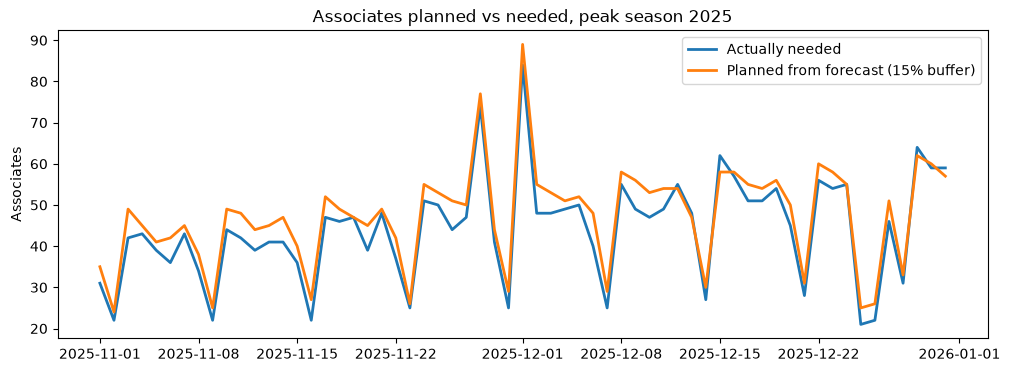

Saved: True


In [6]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.capacity import headcount_needed

images = root / "images"
images.mkdir(exist_ok=True)

conn = sqlite3.connect(config.DB_PATH)
fc = pd.read_sql("select * from forecast_peak_2025", conn, parse_dates=["date"]).set_index("date")
target_uph = round(pd.read_sql("select uph from ops_synthetic", conn)["uph"].median(), 1)

BUFFER = 0.15
fc["planned"] = headcount_needed(fc["forecast_parcels"] * (1 + BUFFER), target_uph, 8, 0.10)
fc["needed"] = headcount_needed(fc["actual_parcels"], target_uph, 8, 0.10)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(fc.index, fc["needed"], label="Actually needed", linewidth=2)
ax.plot(fc.index, fc["planned"], label="Planned from forecast (15% buffer)", linewidth=2)
ax.set_title("Associates planned vs needed, peak season 2025")
ax.set_ylabel("Associates")
ax.legend()
plt.savefig(images / "08_headcount_plan.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", (images / "08_headcount_plan.png").exists())